<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/Module4Gate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mastery Gate Data Visualization Quiz

## 1. `fig, ax = plt.subplots()`
* **`fig` (Figure):** The entire outer canvas or window that holds all plots, titles, and margins.
* **`ax` (Axes):** The specific plotting area inside the figure where data, axes, and labels are drawn.
* **Why prefer it:** This object-oriented style gives explicit control over individual charts, making multi-plot layouts and customizations cleaner and less error-prone than `plt` global state functions.

---

## 2. Choosing the Right Chart
* **Distribution across five regions:** **Box plot** (or **violin plot**) to compare medians, spreads, and outliers side-by-side.
* **Preview all numeric relationships in a table:** **Pair plot** (scatter matrix) for pairwise distributions, or a **correlation heatmap** for correlation strengths.

---

## 3. Right-Skewed Histograms
* **Value to annotate:** The **median**.
* **Why:** Extreme high values in the right tail pull the **mean** upward, whereas the median resists outliers and accurately represents the center of typical values.

---

## 4. Bar Chart Title & Sorting Rules
* **Title Rule 1 (State the takeaway):** Lead with the main insight or conclusion rather than just naming the variables (e.g., *"North Region Leads Q3 Sales"* instead of *"Sales by Region"*).
* **Title Rule 2 (Axes carry the units):** Keep units of measurement on the axis labels rather than cluttering the main title.
* **Sorting Rule:** Sort bars **by value** (descending or ascending), unless categories have a natural order (such as months of the year or age groups).

---

## 5. Pie Charts vs. Alternatives
* **When acceptable:** Only when answering a clear **part-to-whole question** with **three or fewer slices** of noticeably different sizes (4+ slices make wedge comparisons unreliable).
* **Safer alternative:** A **sorted horizontal bar chart**, because human eyes compare bar lengths along a common baseline much more accurately than slice angles or areas.


In [23]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Download & load dataset cleanly
path = kagglehub.dataset_download("danielgrijalvas/movies")
csv_file = next(f for f in os.listdir(path) if f.endswith('.csv'))
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

# Clean string columns safely without turning NaNs into 'nan' text
movies['genre'] = movies['genre'].str.strip().str.title()
movies['rating'] = movies['rating'].str.strip().fillna('Unknown')

# Helper to enforce finished-chart standards consistently
def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

print(f"Loaded fresh movies table: {movies.shape[0]:,} rows, {movies.shape[1]} columns")


Using Colab cache for faster access to the 'movies' dataset.
Loaded fresh movies table: 7,668 rows, 15 columns


=== ITEM 1: LABELLED HISTOGRAM OF GROSS ===


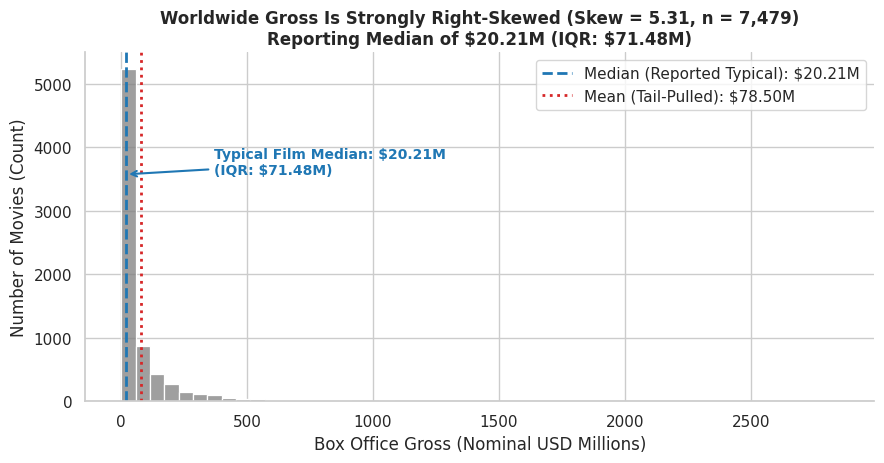

Gross Summary (n=7,479) -> Skew: 5.31 | Median: $20.21M | IQR: $71.48M | Mean: $78.50M


In [24]:
print("=== ITEM 1: LABELLED HISTOGRAM OF GROSS ===")

# --- ORIGINAL PREDICTION (ITEM 1 — UNEDITED) ---
# Prediction (Item 1): Worldwide gross (in $M) will be strongly right-skewed (skew > 4) with most films clustered below $50M and a long tail stretching past $2,000M, so the median will be much lower than the mean and is the honest typical value to report.

valid_gross = movies.dropna(subset=['gross']).copy()
valid_gross['gross_m'] = valid_gross['gross'] / 1e6

n_g = len(valid_gross)
g_med = float(valid_gross['gross_m'].median())
g_iqr = float(valid_gross['gross_m'].quantile(0.75) - valid_gross['gross_m'].quantile(0.25))
g_mean = float(valid_gross['gross_m'].mean())
g_skew = float(valid_gross['gross_m'].skew())
skew_label = "Right-Skewed" if g_skew > 0.5 else ("Left-Skewed" if g_skew < -0.5 else "Roughly Symmetric")

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.histplot(data=valid_gross, x='gross_m', bins=50, color='#7f7f7f', ax=ax)

ax.axvline(g_med, color='#1f77b4', linestyle='--', linewidth=2, label=f'Median (Reported Typical): \\${g_med:.2f}M')
ax.axvline(g_mean, color='#d62728', linestyle=':', linewidth=2, label=f'Mean (Tail-Pulled): \\${g_mean:.2f}M')

y_min, y_max = ax.get_ylim()
ax.annotate(
    f'Typical Film Median: \\${g_med:.2f}M\n(IQR: \\${g_iqr:.2f}M)',
    xy=(g_med, y_max * 0.65),
    xytext=(g_med + 350, y_max * 0.65),
    arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5),
    fontsize=10, fontweight='bold', color='#1f77b4'
)

finish(
    ax,
    f'Worldwide Gross Is Strongly {skew_label} (Skew = {g_skew:.2f}, n = {n_g:,})\nReporting Median of \\${g_med:.2f}M (IQR: \\${g_iqr:.2f}M)',
    'Box Office Gross (Nominal USD Millions)',
    'Number of Movies (Count)'
)
ax.legend()
fig.tight_layout()
plt.show()

print(f"Gross Summary (n={n_g:,}) -> Skew: {g_skew:.2f} | Median: ${g_med:.2f}M | IQR: ${g_iqr:.2f}M | Mean: ${g_mean:.2f}M")
# Result check (Item 1): Predicted strong right skew (>4) with median far below mean; actual skew is 5.31 (n = 7,479), median is $20.21M (IQR $71.48M) vs. mean $78.50M.


=== ITEM 2: SORTED BAR CHART OF GROUPED TOTAL GROSS ===


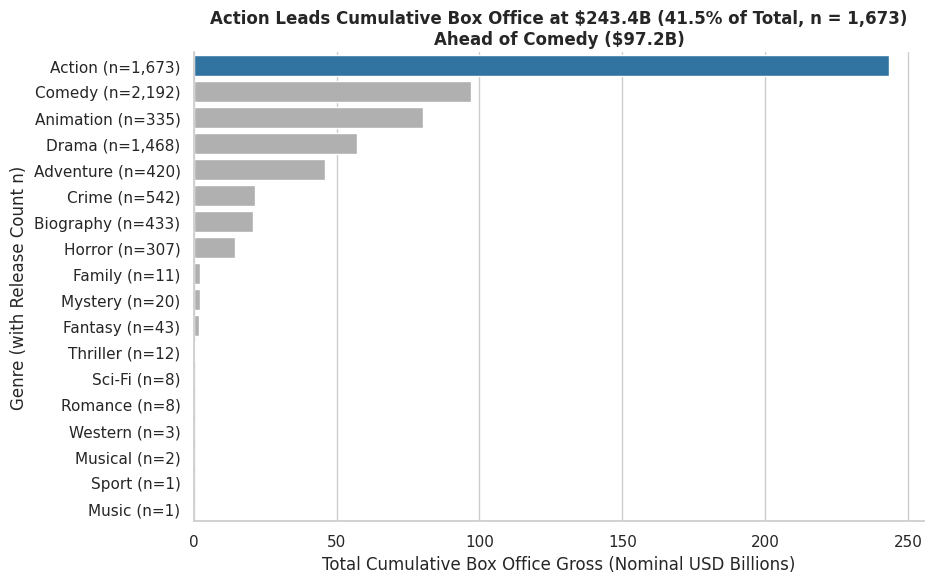

,n,total_b
genre,,
Action,1673,243.44
Comedy,2192,97.18
Animation,335,80.14
Drama,1468,57.15
Adventure,420,45.92


Action share of total box office gross: 41.5%


In [25]:
print("=== ITEM 2: SORTED BAR CHART OF GROUPED TOTAL GROSS ===")

# --- ORIGINAL PREDICTION (ITEM 2 — UNEDITED) ---
# Prediction (Item 2): Action will lead in cumulative total gross across the dataset because it combines high per-film ticket sales with a very large release volume, followed by Comedy and Animation.

genre_totals = (
    valid_gross.groupby('genre')['gross']
    .agg(n='count', total_b=lambda s: s.sum() / 1e9)
    .sort_values(by='total_b', ascending=False)
)

top_g = genre_totals.index[0]
top_total_b = float(genre_totals['total_b'].iloc[0])
top_g_n = int(genre_totals['n'].iloc[0])
second_g = genre_totals.index[1]
second_total_b = float(genre_totals['total_b'].iloc[1])
total_share_pct = (top_total_b / genre_totals['total_b'].sum()) * 100

genre_totals['label'] = [f"{g} (n={int(row['n']):,})" for g, row in genre_totals.iterrows()]
palette_total = {lbl: ('#1f77b4' if i == 0 else '#b0b0b0') for i, lbl in enumerate(genre_totals['label'])}

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.barplot(
    data=genre_totals, x='total_b', y='label',
    palette=palette_total, hue='label', legend=False, ax=ax
)

finish(
    ax,
    f'{top_g} Leads Cumulative Box Office at \\${top_total_b:.1f}B ({total_share_pct:.1f}% of Total, n = {top_g_n:,})\nAhead of {second_g} (\\${second_total_b:.1f}B)',
    'Total Cumulative Box Office Gross (Nominal USD Billions)',
    'Genre (with Release Count n)'
)
fig.tight_layout()
fig.savefig('fig2_total_gross_by_genre.png', dpi=200)
plt.show()

display(genre_totals[['n', 'total_b']].head(5).round(2))
print(f"Action share of total box office gross: {total_share_pct:.1f}%")
# Result check (Item 2): Predicted Action would lead total gross followed by Comedy and Animation; actual order matches — Action ($243.44B, n = 1,673, 41.5% of total), Comedy ($97.18B, n = 2,192), and Animation ($80.14B, n = 335).


=== ITEM 3: GROUPED BOXPLOT OF GROSS BY RATING ===


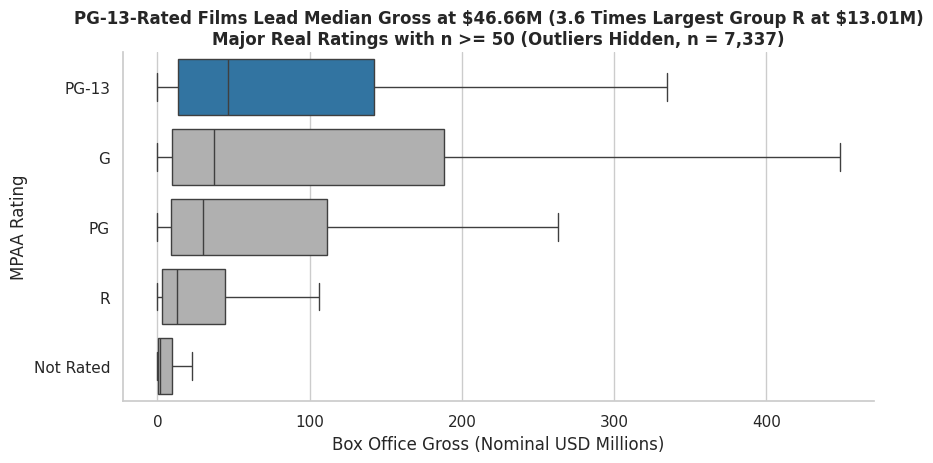

,n,median,iqr
rating,,,
PG-13,2091,46.66,128.91
G,152,36.99,178.56
PG,1222,29.77,102.01
R,3613,13.01,41.31
Not Rated,259,1.69,9.59


In [26]:
print("=== ITEM 3: GROUPED BOXPLOT OF GROSS BY RATING ===")

# --- ORIGINAL PREDICTION (ITEM 3 — UNEDITED) ---
# Prediction (Item 3): Family-oriented ratings ('PG', 'G', and 'PG-13') will have noticeably higher median gross than 'R' and 'Not Rated' releases because wide-appeal theatrical releases reach larger global audiences.

# Outlier & Filter Decision: Raw gross reaches $2,847.25M (skew = 5.31), which flattens every box into an unreadable line if plotted raw.
# Keep all valid gross rows intact in the master DataFrame, filter the boxplot to real MPAA ratings with at least 50 releases while excluding synthetic 'Unknown' (n = 54) missing-value fills, and set showfliers=False so medians, Q1/Q3 boxes, and 1.5*IQR whiskers remain exact without extreme luxury blockbusters crushing the scale.

rating_counts = valid_gross['rating'].value_counts()
major_ratings = rating_counts[rating_counts >= 50].index

sub_rating = valid_gross[
    valid_gross['rating'].isin(major_ratings) & (valid_gross['rating'] != 'Unknown')
].copy()

rating_stats = sub_rating.groupby('rating')['gross_m'].agg(
    n='count',
    median='median',
    iqr=lambda s: s.quantile(0.75) - s.quantile(0.25)
).sort_values(by='median', ascending=False)

rating_order = rating_stats.index.tolist()
top_r = rating_order[0]
top_r_med = float(rating_stats.loc[top_r, 'median'])
ref_r = rating_stats['n'].idxmax()
ref_med = float(rating_stats.loc[ref_r, 'median'])
r_ratio = top_r_med / ref_med

palette_rating = {r: ('#1f77b4' if r == top_r else '#b0b0b0') for r in rating_order}

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(
    data=sub_rating, x='gross_m', y='rating', order=rating_order,
    palette=palette_rating, hue='rating', legend=False,
    showfliers=False, ax=ax
)

finish(
    ax,
    f'{top_r}-Rated Films Lead Median Gross at \\${top_r_med:.2f}M ({r_ratio:.1f} Times Largest Group {ref_r} at \\${ref_med:.2f}M)\nMajor Real Ratings with n >= 50 (Outliers Hidden, n = {len(sub_rating):,})',
    'Box Office Gross (Nominal USD Millions)',
    'MPAA Rating'
)
fig.tight_layout()
plt.show()

display(rating_stats.round(2))
# Result check (Item 3): Predicted PG, G, and PG-13 would sit noticeably higher than R and Not Rated; actual medians confirm PG-13 leads at $46.66M (n = 2,091, IQR $128.91M)—3.6 times the largest rating group R ($13.01M, n = 3,613)—ahead of G ($36.99M, n = 152) and PG ($29.77M, n = 1,222), while Not Rated sits at $1.69M (n = 259). Synthetic 'Unknown' (n = 54) was excluded because it represents missing MPAA records rather than a real rating tier.


=== ITEM 4: PAIRPLOT OF BUDGET, GROSS, VOTES, AND SCORE ===


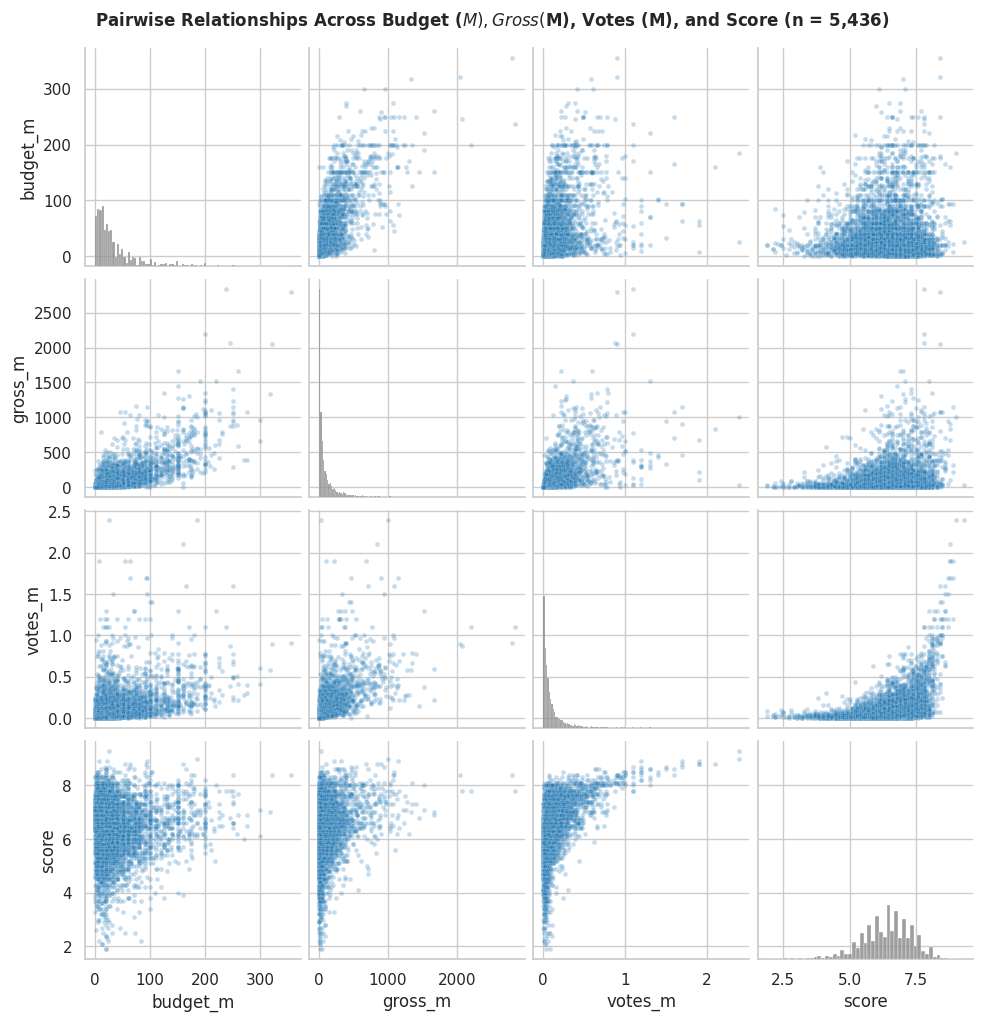


=== ITEM 5: ANNOTATED CORRELATION HEATMAP ===


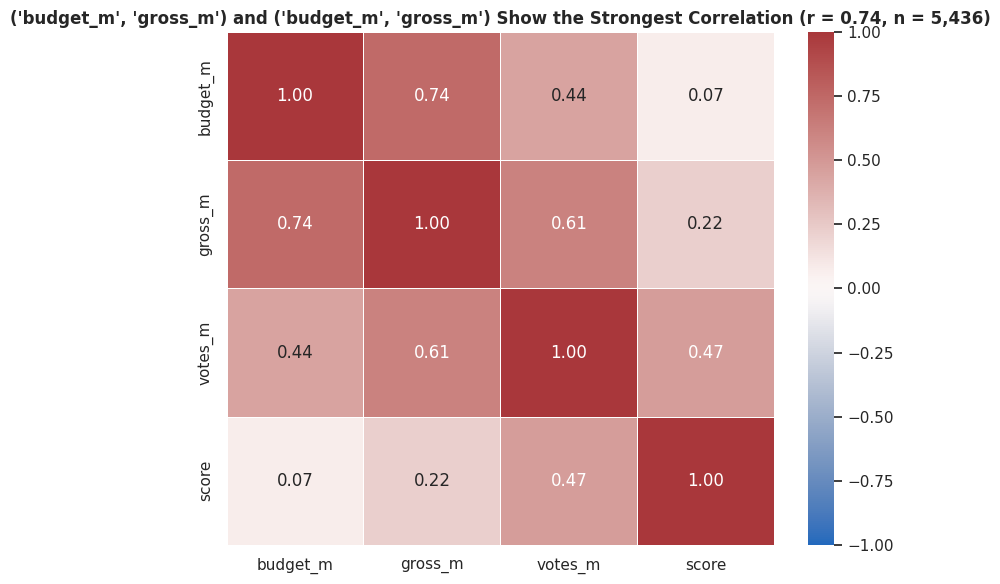

Exact Correlation Matrix:
          budget_m  gross_m  votes_m  score
budget_m     1.000    0.740    0.440  0.072
gross_m      0.740    1.000    0.615  0.222
votes_m      0.440    0.615    1.000  0.474
score        0.072    0.222    0.474  1.000


In [27]:
print("=== ITEM 4: PAIRPLOT OF BUDGET, GROSS, VOTES, AND SCORE ===")

# --- ORIGINAL PREDICTION (ITEM 4 — UNEDITED) ---
# Prediction (Item 4): 'budget' and 'gross' will look most linearly related in the scatter matrix, followed by 'votes' and 'gross', while 'score' (IMDb critic/user rating) will show much weaker linear correlation with box office dollars.

rel_cols = ['budget', 'gross', 'votes', 'score']
valid_rel = movies[rel_cols].dropna().copy()
valid_rel['budget_m'] = valid_rel['budget'] / 1e6
valid_rel['gross_m'] = valid_rel['gross'] / 1e6
valid_rel['votes_m'] = valid_rel['votes'] / 1e6
plot_cols = ['budget_m', 'gross_m', 'votes_m', 'score']

g = sns.pairplot(
    valid_rel[plot_cols],
    plot_kws={'alpha': 0.25, 's': 12, 'color': '#1f77b4'},
    diag_kws={'color': '#7f7f7f'}
)
g.fig.suptitle(
    f'Pairwise Relationships Across Budget ($M), Gross ($M), Votes (M), and Score (n = {len(valid_rel):,})',
    y=1.02, fontsize=12, fontweight='bold'
)
plt.show()

# Result check (Item 4): Predicted budget and gross would look most linearly related followed by votes and gross, with score much weaker; actual pairplot confirms budget_m and gross_m show the clearest upward linear fan (r = 0.740), followed by votes_m and gross_m (r = 0.615), while score shows near-zero linear correlation with budget_m (r = 0.072).

print("\n=== ITEM 5: ANNOTATED CORRELATION HEATMAP ===")

# --- ORIGINAL PREDICTION (ITEM 5 — UNEDITED) ---
# Prediction (Item 5): ('budget_m', 'gross_m') will be the strongest correlation pair in the matrix (r around 0.70–0.75).

corr_mat = valid_rel[plot_cols].corr()

# Compute strongest pair dynamically from upper triangle of correlation matrix (never typed by hand)
upper_pairs = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1)).stack()
best_pair = upper_pairs.abs().idxmax()
best_r = float(upper_pairs[best_pair])

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(
    corr_mat, annot=True, fmt='.2f', cmap='vlag',
    vmin=-1, vmax=1, linewidths=0.5, ax=ax
)
col_a, col_b = best_pair
ax.set_title(
    f'{col_a} and {col_b} Show the Strongest Correlation (r = {best_r:.2f}, n = {len(valid_rel):,})',
    fontsize=12, fontweight='bold'
)

ax.set_title(
    f'{best_pair} and {best_pair} Show the Strongest Correlation (r = {best_r:.2f}, n = {len(valid_rel):,})',
    fontsize=12, fontweight='bold'
)
fig.tight_layout()
fig.savefig('fig5_correlation_heatmap.png', dpi=200)
plt.show()

print("Exact Correlation Matrix:")
print(corr_mat.round(3))
# Result check (Item 5): Predicted ('budget_m', 'gross_m') would be strongest (0.70–0.75); actual best_pair computed from the upper triangle is ('budget_m', 'gross_m') with r = 0.740 (n = 5,436).
